In [1]:
# 2026_10_06
# Capstone: Monero: price, volume, 20 and 50 moving average

In [2]:
# Step 1: Import libraries
# ----------------------------------------
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
import numpy as np

In [4]:
# ============================================================
# STEP 1: DOWNLOAD MONERO DATA FROM COINGECKO
# ============================================================


# This is the URL for CoinGecko's Monero market data API.
url = "https://api.coingecko.com/api/v3/coins/monero/market_chart"


# These are the settings we send with our API request.
params = {
    "vs_currency": "usd",  # Get Monero prices in US Dollars
    "days": "180",         # Get the last 180 days of data
    "interval": "daily"    # Get one data point per day
}


# requests.get() sends a request to the API.
# The API then sends data back to Python.
response = requests.get(url, params=params)


# raise_for_status() checks if the API request was successful.
# If there is an error, Python will display the error instead
# of continuing with incorrect or missing data.
response.raise_for_status()


# .json() converts the API response into Python data.
# The result is usually a dictionary containing lists.
data = response.json()


In [5]:
# ============================================================
# STEP 2: CREATE A PANDAS DATAFRAME
# ============================================================


# The API gives us price data in this format:
#
# [timestamp, price]
#
# Example:
# [1725148800000, 59000]
#
# pd.DataFrame() converts this data into a table.
prices = pd.DataFrame(
    data["prices"],
    columns=["timestamp", "Close"]
)

# "timestamp" = the date and time in milliseconds
# "Close" = the Monero price


# The API gives us volume data in this format:
#
# [timestamp, volume]
#
# We also convert this into a DataFrame.
volumes = pd.DataFrame(
    data["total_volumes"],
    columns=["timestamp", "Volume"]
)

# "Volume" represents the amount of Monero trading activity.

In [6]:
# ============================================================
# STEP 3: CONVERT THE TIMESTAMP INTO A REAL DATE
# ============================================================


# pd.to_datetime() converts timestamps into readable dates.
#
# unit="ms" means the timestamp is measured in milliseconds.
prices["Date"] = pd.to_datetime(
    prices["timestamp"],
    unit="ms"
)


# We do the same thing for the volume DataFrame.
volumes["Date"] = pd.to_datetime(
    volumes["timestamp"],
    unit="ms"
)

In [7]:
# ============================================================
# STEP 4: COMBINE PRICE AND VOLUME DATA
# ============================================================


# merge() combines two DataFrames together.
#
# We combine them using the "Date" column.
#
# on="Date" tells pandas which column to use when matching data.
df = prices.merge(
    volumes,
    on="Date"
)


# Select only the columns we want to keep.
#
# We do not need the original timestamp columns anymore.
df = df[["Date", "Close", "Volume"]]


# sort_values() puts the data in chronological order.
#
# ascending=True means oldest dates come first.
df = df.sort_values(
    "Date",
    ascending=True
)


# set_index() makes the Date column the index of the DataFrame.
#
# An index helps us work with time-series data.
df = df.set_index("Date")


# Display the first 5 rows of the original data.
#
# head() shows the first 5 rows by default.
print("RAW MONERO DATA")
print(df.head())

RAW MONERO DATA
                 Close        Volume
Date                                
2026-04-10  346.612628  8.044576e+07
2026-04-11  344.143236  1.080376e+08
2026-04-12  338.640269  7.386451e+07
2026-04-13  335.377509  8.065731e+07
2026-04-14  346.566741  1.048249e+08


In [8]:
# ============================================================
# STEP 7: MOVING AVERAGES: 20 and 50
# ============================================================


# rolling(20) creates a moving window of 20 days.
#
# mean() calculates the average.
#
# This gives us the average Monero price over the last 20 days.
df["ma_20"] = df["Close"].rolling(20).mean()


# Average Monero price over the last 50 days.
df["ma_50"] = df["Close"].rolling(50).mean()

In [9]:
# ============================================================
# STEP 14: CLEAN THE DATA
# ============================================================


# Some rows contain missing values (NaN).
#
# This happens because:
#
# - pct_change() needs a previous day
# - moving averages need several days of data
# - lag features need previous days
# - tomorrow's price is unknown for the final row
#
# dropna() removes rows containing missing values.
df = df.dropna()

In [10]:
# ============================================================
# STEP 15: VIEW THE FINAL DATASET
# ============================================================


# Display the first 5 rows of the completed dataset.
print("\nFINAL FEATURE ENGINEERED DATASET")
print(df.head())


# Display all column names.
print("\nFINAL COLUMNS")
print(df.columns.tolist())


# Display the shape of the dataset.
#
# shape returns:
#
# (number of rows, number of columns)
print("\nDATASET SHAPE")
print(df.shape)


FINAL FEATURE ENGINEERED DATASET
                 Close        Volume       ma_20       ma_50
Date                                                        
2026-05-29  354.023104  1.450772e+08  392.411070  379.101073
2026-05-30  396.793626  1.750653e+08  391.753060  380.104693
2026-05-31  370.259454  2.247502e+08  389.793735  380.627017
2026-06-01  367.346880  1.046001e+08  387.347292  381.201150
2026-06-02  343.916288  1.473069e+08  383.977673  381.371925

FINAL COLUMNS
['Close', 'Volume', 'ma_20', 'ma_50']

DATASET SHAPE
(132, 4)


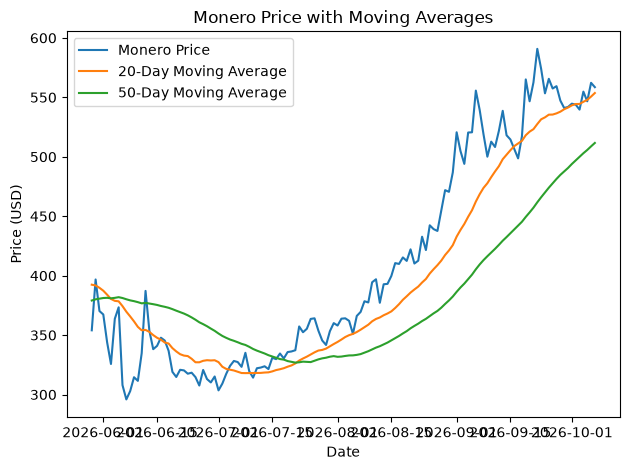

In [11]:
# ============================================================
# VISUALIZATION 1:
# MONERO PRICE VS MOVING AVERAGES
# ============================================================


# plt.figure() creates a new chart.
#
# We create a new figure for every visualization.
plt.figure()


# plt.plot() creates a line chart.
#
# df.index contains our dates.
#
# df["Close"] contains MONERO prices.
plt.plot(
    df.index,
    df["Close"],
    label="Monero Price"
)


# Plot the 20-day moving average.
plt.plot(
    df.index,
    df["ma_20"],
    label="20-Day Moving Average"
)


# Plot the 50-day moving average.
plt.plot(
    df.index,
    df["ma_50"],
    label="50-Day Moving Average"
)


# Add a title to the chart.
plt.title("Monero Price with Moving Averages")


# Label the X-axis.
plt.xlabel("Date")


# Label the Y-axis.
plt.ylabel("Price (USD)")


# legend() displays the labels for each line.
plt.legend()


# tight_layout() helps prevent chart elements from overlapping.
plt.tight_layout()


# show() displays the chart.
plt.show()

In [12]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [13]:
# New chart with monthly and improved dates

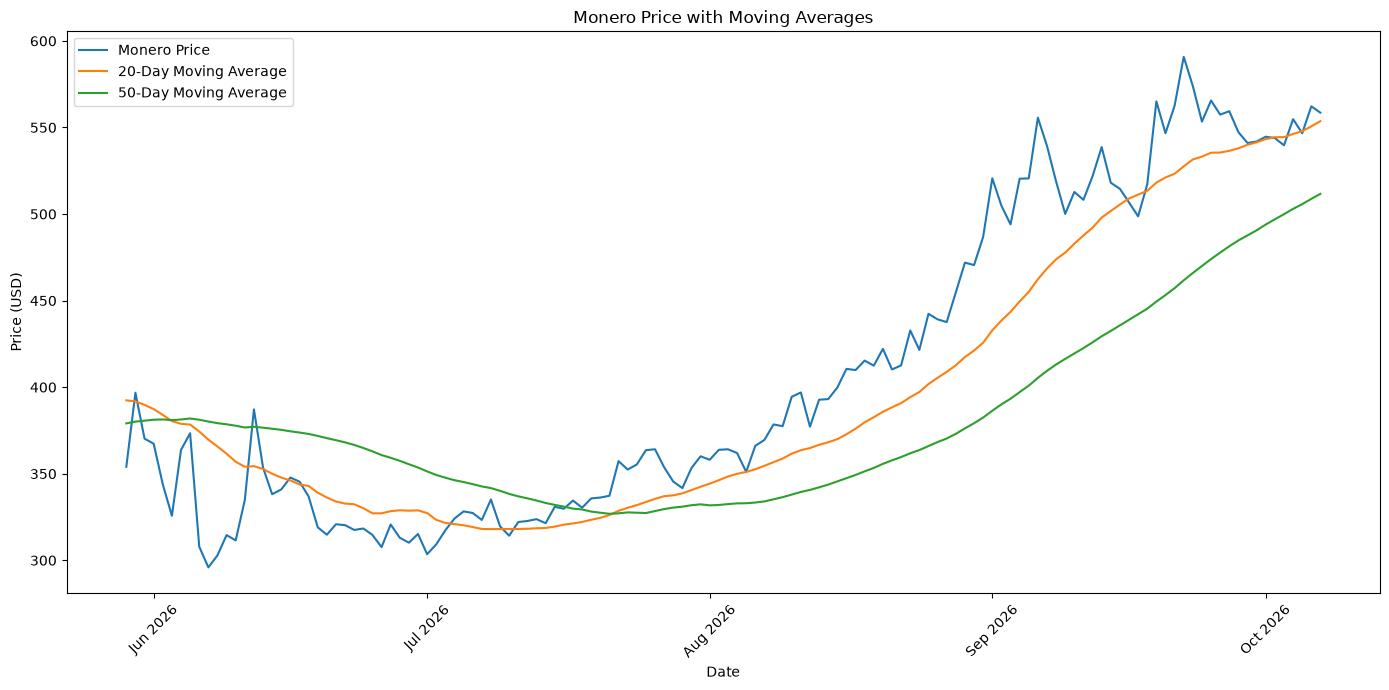

In [14]:
plt.figure(figsize=(14, 7))

# Plot Monero price
plt.plot(
    df.index,
    df["Close"],
    label="Monero Price"
)

# Plot 20-day moving average
plt.plot(
    df.index,
    df["ma_20"],
    label="20-Day Moving Average"
)

# Plot 50-day moving average
plt.plot(
    df.index,
    df["ma_50"],
    label="50-Day Moving Average"
)

# Add title
plt.title("Monero Price with Moving Averages")

# Label axes
plt.xlabel("Date")
plt.ylabel("Price (USD)")

# Show only a reasonable number of dates
ax = plt.gca()

# Put a date label roughly every month
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))


# Rotate the date labels so they don't overlap
plt.xticks(rotation=45)

# Legend
plt.legend()

# Prevent overlapping elements
plt.tight_layout()

plt.show()


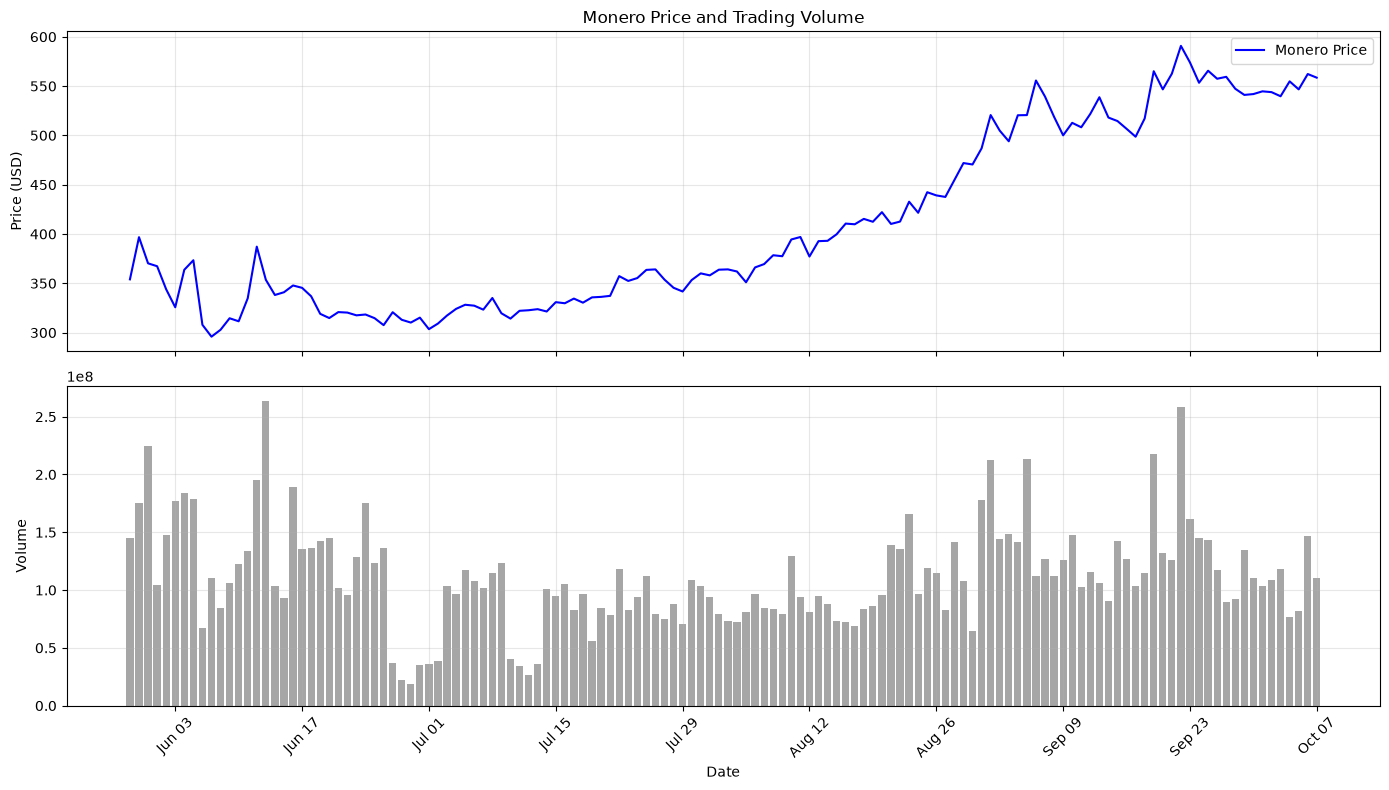

In [16]:
# Plot price vs. volume
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Create the figure with 2 stacked plots
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(14, 8),
    sharex=True
)

# -------------------------
# Price chart
# -------------------------
ax1.plot(
    df.index,
    df["Close"],
    color="blue",
    label="Monero Price"
)

ax1.set_title("Monero Price and Trading Volume")
ax1.set_ylabel("Price (USD)")
ax1.legend()
ax1.grid(True, alpha=0.3)


# -------------------------
# Volume chart
# -------------------------
ax2.bar(
    df.index,
    df["Volume"],
    color="gray",
    alpha=0.7
)

ax2.set_ylabel("Volume")
ax2.set_xlabel("Date")
ax2.grid(True, alpha=0.3)


# -------------------------
# Format dates
# -------------------------

# Show a date approximately every 2 weeks
ax2.xaxis.set_major_locator(mdates.DayLocator(interval=14))

# Format dates as "Jan 15"
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

# Rotate date labels
plt.xticks(rotation=45)

# Prevent overlapping elements
plt.tight_layout()

plt.show()

